In [1]:
# Project Title:
# Analyze E-Commerce Sales to Improve Customer Conversion and Retention

# Objectives:
# 1. Analyze overall sales and revenue performance
# 2. Identify high-performing product categories and subcategories
# 3. Analyze customer segments and repeat purchasing behavior
# 4. Identify cancellation and return patterns
# 5. Analyze delivery performance and its relationship with reviews
# 6. Identify factors affecting customer retention
# 7. Identify profitable products and categories
# 8. Generate business insights for improving conversion and retention

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

sns.set_theme(style="whitegrid")

In [10]:
import pandas as pd

customer_path = r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\customer_datasets_cleaned.xlsx"

customers = pd.read_excel(
    customer_path,
    sheet_name="Customers_dataset"
)

print("Customers loaded successfully!")
print(customers.shape)
display(customers.head())

Customers loaded successfully!
(90000, 5)


,customer_id,customer_zip_code,gender,age_group,customer_segment
0,C00001,690511,Female,36-45,Loyal
1,C00002,509152,Male,26-35,New
2,C00003,477335,Male,26-35,Loyal
3,C00004,140413,Female,65+,Loyal
4,C00005,700009,Male,26-35,Loyal


In [11]:
orders = pd.read_excel(
    r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\orders_datasets_cleaned.xlsx",
    sheet_name="Orders_dataset"
)

print("Orders loaded:", orders.shape)

Orders loaded: (99999, 13)


In [12]:
order_items = pd.read_excel(
    r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\order_items_datasets_cleaned.xlsx",
    sheet_name="Order_items_dataset"
)

print("Order Items loaded:", order_items.shape)

Order Items loaded: (150004, 19)


In [13]:
reviews = pd.read_excel(
    r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\order_reviews_datasets_cleaned.xlsx",
    sheet_name="Order_reviews_dataset"
)

print("Reviews loaded:", reviews.shape)

Reviews loaded: (97019, 7)


In [14]:
products = pd.read_excel(
    r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\products_datasets_cleaned.xlsx",
    sheet_name="Products_dataset"
)

print("Products loaded:", products.shape)

Products loaded: (32951, 16)


In [15]:
geolocation = pd.read_excel(
    r"C:\Users\ARPIT TYAGI\OneDrive\Desktop\NIIT\7\Phase 1 (Datasets)\Cleaned datasets\geolocation_datasets_cleaned.xlsx",
    sheet_name="Geolocation_dataset"
)

print("Geolocation loaded:", geolocation.shape)

Geolocation loaded: (128111, 11)


In [16]:
print("Customers   :", customers.shape)
print("Orders      :", orders.shape)
print("Order Items :", order_items.shape)
print("Reviews     :", reviews.shape)
print("Products    :", products.shape)
print("Geolocation :", geolocation.shape)

Customers   : (90000, 5)
Orders      : (99999, 13)
Order Items : (150004, 19)
Reviews     : (97019, 7)
Products    : (32951, 16)
Geolocation : (128111, 11)


In [17]:
datasets = {
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Customers": customers,
    "Reviews": reviews,
    "Geolocation": geolocation
}

for name, df in datasets.items():
    print("\n" + "="*60)
    print(name)
    print("="*60)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    display(df.head())


Orders
Rows: 99999
Columns: 13


,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,Delivery Delay,Delivery_Status,Unnamed: 11,Unnamed: 12
0,O00001,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03,60.0,60 days late,99999,NaN
1,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,-26.0,26 days early,NaN,NaN
2,O00003,C19454,cancelled,UPI,2021-08-06,NaT,NaT,NaT,NaT,NaN,NaN,0,NaN
3,O00004,C67148,delivered,UPI,2025-07-07,2025-07-07,2025-10-06,2025-10-12,2025-07-12,92.0,92 days late,0,NaN
4,O00005,C56280,delivered,Net Banking,2024-03-30,2024-03-30,2024-03-31,2024-04-04,2024-04-07,-3.0,3 days early,0,NaN



Order Items
Rows: 150004
Columns: 19


,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost,Outlier,Gross Amount,Discount Amount,Net Product Amount,Total Cost Including Shipping,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18
0,OI000001,O00001,1.0,P28355,7020.0,6.54,713.72,Normal,7020.0,459.108,6560.892,7274.612,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,OI000002,O00002,1.0,P04408,7590.0,20.56,1212.02,Normal,7590.0,1560.504,6029.496,7241.516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,OI000003,O00002,2.0,P14887,14360.0,24.67,1478.39,Normal,28720.0,7085.224,21634.776,23113.166,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,OI000004,O00003,2.0,P02014,1530.0,12.06,155.12,Normal,3060.0,369.036,2690.964,2846.084,6.0,NaN,0.0,NaN,NaN,NaN,NaN
4,OI000005,O00003,1.0,P27255,1560.0,10.51,188.03,Normal,1560.0,163.956,1396.044,1584.074,6.0,1.0,0.0,NaN,NaN,NaN,NaN



Products
Rows: 32951
Columns: 16


...

,customer_id,customer_zip_code,gender,age_group,customer_segment
0,C00001,690511,Female,36-45,Loyal
1,C00002,509152,Male,26-35,New
2,C00003,477335,Male,26-35,Loyal
3,C00004,140413,Female,65+,Loyal
4,C00005,700009,Male,26-35,Loyal



Reviews
Rows: 97019
Columns: 7


,T,order_id,review_score,review_comment_message,review_date,Unnamed: 5,Unnamed: 6
0,R00001,O41195,5,No Comment,NaT,NaN,NaN
1,R00002,O29304,5,Order cancelled by the seller.,NaT,NaN,NaN
2,R00003,O57427,5,Payment issue led to cancellation.,NaT,NaN,NaN
3,R00004,O12705,5,No Comment,2022-10-22,NaN,NaN
4,R00005,O43324,1,No Comment,NaT,NaN,NaN



Geolocation
Rows: 128111
Columns: 11


,geolocation_zip_code,geolocation_city,geolocation_state,geolocation_lat,geolocation_lng,region,Column1,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,744301,Sawai,Andaman & Nicobar Islands,7.52,93.60,East,NaN,128112.0,NaN,NaN,NaN
1,744301,Mus,Andaman & Nicobar Islands,9.23,92.78,East,NaN,NaN,NaN,NaN,NaN
2,744301,Kakana,Andaman & Nicobar Islands,9.12,92.80,East,NaN,NaN,NaN,NaN,NaN
3,744301,Carnicobar,Andaman & Nicobar Islands,9.18,92.77,East,NaN,NaN,NaN,NaN,NaN
4,744301,Lapathy,Andaman & Nicobar Islands,9.18,92.77,East,NaN,NaN,NaN,NaN,NaN


In [18]:
for name, df in datasets.items():
    print("\n", name)
    display(df.dtypes)


 Orders


order_id                                 object
customer_id                              object
order_status                             object
payment_type                             object
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_shipping_date    datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
Delivery Delay                          float64
Delivery_Status                          object
Unnamed: 11                              object
Unnamed: 12                             float64
dtype: object


 Order Items


order_item_id                     object
order_id                          object
quantity                         float64
product_id                        object
unit_price                       float64
discount(%)                      float64
shipping_cost                    float64
Outlier                           object
Gross Amount                     float64
Discount Amount                  float64
Net Product Amount               float64
Total Cost Including Shipping    float64
Unnamed: 12                      float64
Unnamed: 13                      float64
Unnamed: 14                      float64
Unnamed: 15                      float64
Unnamed: 16                       object
Unnamed: 17                      float64
Unnamed: 18                      float64
dtype: object


 Products


...

customer_id          object
customer_zip_code     int64
gender               object
age_group            object
customer_segment     object
dtype: object


 Reviews


T                                 object
order_id                          object
review_score                       int64
review_comment_message            object
review_date               datetime64[ns]
Unnamed: 5                       float64
Unnamed: 6                       float64
dtype: object


 Geolocation


geolocation_zip_code      int64
geolocation_city         object
geolocation_state        object
geolocation_lat         float64
geolocation_lng         float64
region                   object
Column1                 float64
Unnamed: 7              float64
Unnamed: 8              float64
Unnamed: 9               object
Unnamed: 10             float64
dtype: object

In [19]:
for name, df in datasets.items():
    print("\n" + "="*50)
    print(name)
    
    missing = df.isnull().sum()
    missing = missing[missing > 0].sort_values(ascending=False)
    
    display(missing)


Orders


Unnamed: 12                      99994
Unnamed: 11                      99984
order_delivered_customer_date     8028
Delivery Delay                    8028
Delivery_Status                   8028
order_approved_at                 5048
order_delivered_shipping_date     5048
order_estimated_delivery_date     5048
dtype: int64


Order Items


Unnamed: 15                      150004
Unnamed: 18                      150001
Unnamed: 17                      149999
Unnamed: 16                      149999
Unnamed: 14                      149997
Net Product Amount                    4
Unnamed: 13                           4
Unnamed: 12                           4
Total Cost Including Shipping         4
order_item_id                         4
order_id                              4
Gross Amount                          4
Outlier                               4
shipping_cost                         4
discount(%)                           4
unit_price                            4
product_id                            4
quantity                              4
Discount Amount                       4
dtype: int64


Products


...

Series([], dtype: int64)


Reviews


Unnamed: 5     97019
Unnamed: 6     97014
review_date    47554
dtype: int64


Geolocation


Column1             128111
Unnamed: 8          128111
Unnamed: 7          128107
Unnamed: 10         128106
Unnamed: 9          128104
geolocation_city         1
dtype: int64

In [20]:
for name, df in datasets.items():
    print(name, "duplicates:", df.duplicated().sum())

Orders duplicates: 0
Order Items duplicates: 2
Products duplicates: 0
Customers duplicates: 0
Reviews duplicates: 0
Geolocation duplicates: 0


In [21]:
def remove_unnecessary_columns(df):
    cols_to_remove = [
        col for col in df.columns
        if col.startswith("Unnamed") or col == "Column1"
    ]
    return df.drop(columns=cols_to_remove, errors='ignore')


orders = remove_unnecessary_columns(orders)
order_items = remove_unnecessary_columns(order_items)
products = remove_unnecessary_columns(products)
customers = remove_unnecessary_columns(customers)
reviews = remove_unnecessary_columns(reviews)
geolocation = remove_unnecessary_columns(geolocation)

print(orders.columns)
print(order_items.columns)
print(products.columns)
print(customers.columns)
print(reviews.columns)

Index(['order_id', 'customer_id', 'order_status', 'payment_type',
       'order_purchase_timestamp', 'order_approved_at',
       'order_delivered_shipping_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date', 'Delivery Delay', 'Delivery_Status'],
      dtype='object')
Index(['order_item_id', 'order_id', 'quantity', 'product_id', 'unit_price',
       'discount(%)', 'shipping_cost', 'Outlier', 'Gross Amount',
       'Discount Amount', 'Net Product Amount',
       'Total Cost Including Shipping'],
      dtype='object')
Index(['product_id', 'Category_name', 'sub_category_name', 'product_weight_g',
       'brand', 'cost_price', 'selling_price', 'stock_availability',
       'Selling Price < Cost Price', 'Profit', 'Profit Margin'],
      dtype='object')
Index(['customer_id', 'customer_zip_code', 'gender', 'age_group',
       'customer_segment'],
      dtype='object')
Index(['T', 'order_id', 'review_score', 'review_comment_message',
       'review_date'],
      dtype=

In [22]:
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_shipping_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

reviews['review_date'] = pd.to_datetime(
    reviews['review_date'],
    errors='coerce'
)

orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99999 entries, 0 to 99998
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99999 non-null  object        
 1   customer_id                    99999 non-null  object        
 2   order_status                   99999 non-null  object        
 3   payment_type                   99999 non-null  object        
 4   order_purchase_timestamp       99999 non-null  datetime64[ns]
 5   order_approved_at              94951 non-null  datetime64[ns]
 6   order_delivered_shipping_date  94951 non-null  datetime64[ns]
 7   order_delivered_customer_date  91971 non-null  datetime64[ns]
 8   order_estimated_delivery_date  94951 non-null  datetime64[ns]
 9   Delivery Delay                 91971 non-null  float64       
 10  Delivery_Status                91971 non-null  object        
dtypes: datetime64[n

In [23]:
print("Orders Statistics")
display(orders.describe(include='all'))

print("\nOrder Items Statistics")
display(order_items.describe())

print("\nProducts Statistics")
display(products.describe())

print("\nCustomers Statistics")
display(customers.describe(include='all'))

Orders Statistics


,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,Delivery Delay,Delivery_Status
count,99999,99999,99999,99999,99999,94951,94951,91971,94951,91971.000000,91971
unique,99999,51895,4,4,NaN,NaN,NaN,NaN,NaN,NaN,302
top,O00001,C56634,delivered,UPI,NaN,NaN,NaN,NaN,NaN,NaN,1 days late
freq,1,15,84971,55055,NaN,NaN,NaN,NaN,NaN,NaN,1774
mean,NaN,NaN,NaN,NaN,2023-07-24 21:45:12.015120384,2023-08-06 06:09:56.240165888,2023-09-12 09:48:11.230213376,2023-10-04 20:09:28.822780928,2023-08-24 21:11:59.651188480,40.927999,NaN
min,NaN,NaN,NaN,NaN,2021-04-01 00:00:00,2021-04-01 00:00:00,2021-04-01 00:00:00,2021-04-04 00:00:00,2021-04-03 00:00:00,-60.000000,NaN
25%,NaN,NaN,NaN,NaN,2022-07-09 00:00:00,2022-07-19 00:00:00,2022-08-22 00:00:00,2022-09-11 00:00:00,2022-08-06 00:00:00,-1.000000,NaN
50%,NaN,NaN,NaN,NaN,2023-08-26 00:00:00,2023-09-08 00:00:00,2023-10-13 00:00:00,2023-10-31 00:00:00,2023-09-28 00:00:00,30.000000,NaN
75%,NaN,NaN,NaN,NaN,2024-09-22 00:00:00,2024-10-04 00:00:00,2024-11-03 00:00:00,2024-11-20 00:00:00,2024-10-20 00:00:00,81.000000,NaN
max,NaN,NaN,NaN,NaN,2025-09-30 00:00:00,2026-01-26 00:00:00,2026-04-20 00:00:00,2026-07-20 00:00:00,2025-11-29 00:00:00,271.000000,NaN



Order Items Statistics


,quantity,unit_price,discount(%),shipping_cost,Gross Amount,Discount Amount,Net Product Amount,Total Cost Including Shipping
count,150000.00000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,1.28356,6781.045333,13.526562,722.353992,7886.511600,1523.352219,6363.159381,7085.513373
std,0.52342,12494.025679,9.086881,1610.289245,12725.432709,4126.271587,9109.155843,10561.405807
min,1.00000,50.000000,0.000000,5.000000,50.000000,0.000000,39.845000,44.845000
25%,1.00000,2020.000000,6.730000,178.320000,2410.000000,156.620000,2156.931000,2375.127750
50%,1.00000,4030.000000,12.280000,380.930000,4880.000000,481.647000,4356.217000,4802.013500
75%,1.00000,7640.000000,18.670000,739.080000,9690.000000,1423.972000,7996.446750,8823.929000
max,3.00000,149760.000000,52.490000,29830.680000,149760.000000,74272.626000,127026.810000,148538.169000



Products Statistics


,product_weight_g,cost_price,selling_price,Profit,Profit Margin
count,32951.000000,32951.000000,32951.000000,32951.000000,32951.000000
mean,2278.448514,16498.051319,20421.360505,3923.309186,0.206908
std,4285.771330,23833.271209,29336.864189,6367.429400,0.081115
min,2.000000,40.000000,50.000000,1.000000,0.020000
25%,300.000000,3315.000000,4340.000000,890.000000,0.144164
50%,700.000000,8420.000000,10560.000000,1900.000000,0.199241
75%,1900.000000,13890.000000,17250.000000,3550.000000,0.258789
max,40425.000000,133140.000000,149760.000000,50080.000000,0.560976



Customers Statistics


,customer_id,customer_zip_code,gender,age_group,customer_segment
count,90000,90000.000000,90000,90000,90000
unique,90000,NaN,2,6,3
top,C00001,NaN,Male,36-45,New
freq,1,NaN,59744,32400,45211
mean,NaN,516339.295267,NaN,NaN,NaN
std,NaN,203712.734399,NaN,NaN,NaN
min,NaN,110001.000000,NaN,NaN,NaN
25%,NaN,370140.000000,NaN,NaN,NaN
50%,NaN,524127.000000,NaN,NaN,NaN
75%,NaN,686501.250000,NaN,NaN,NaN


In [24]:
# Merge Orders with Customers
master = orders.merge(
    customers,
    on='customer_id',
    how='left'
)

# Merge Order Items
master = master.merge(
    order_items,
    on='order_id',
    how='left'
)

# Merge Products
master = master.merge(
    products,
    on='product_id',
    how='left',
    suffixes=('', '_product')
)

print("Master Dataset Shape:", master.shape)

display(master.head())

Master Dataset Shape: (183482, 36)


,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date,Delivery Delay,Delivery_Status,customer_zip_code,gender,age_group,customer_segment,order_item_id,quantity,product_id,unit_price,discount(%),shipping_cost,Outlier,Gross Amount,Discount Amount,Net Product Amount,Total Cost Including Shipping,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability,Selling Price < Cost Price,Profit,Profit Margin
0,O00001,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03,60.0,60 days late,413514,Male,46-55,Loyal,OI000001,1.0,P28355,7020.0,6.54,713.72,Normal,7020.0,459.108,6560.892,7274.612,sports_leisure,Novelty Items,1325.0,Generic Indian,5330.0,7020.0,In Stock,OK,1690.0,0.240741
1,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,-26.0,26 days early,523230,Male,36-45,New,OI000002,1.0,P04408,7590.0,20.56,1212.02,Normal,7590.0,1560.504,6029.496,7241.516,sports_leisure,Novelty Items,24700.0,Generic Indian,6190.0,7590.0,In Stock,OK,1400.0,0.184453
2,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31,-26.0,26 days early,523230,Male,36-45,New,OI000003,2.0,P14887,14360.0,24.67,1478.39,Normal,28720.0,7085.224,21634.776,23113.166,health_beauty,Gifts,400.0,Generic Indian,11720.0,14360.0,In Stock,OK,2640.0,0.183844
3,O00003,C19454,cancelled,UPI,2021-08-06,NaT,NaT,NaT,NaT,NaN,NaN,532186,Female,46-55,Returning,OI000004,2.0,P02014,1530.0,12.06,155.12,Normal,3060.0,369.036,2690.964,2846.084,garden_tools,General Merchandise,5400.0,Generic Indian,1300.0,1530.0,In Stock,OK,230.0,0.150327
4,O00003,C19454,cancelled,UPI,2021-08-06,NaT,NaT,NaT,NaT,NaN,NaN,532186,Female,46-55,Returning,OI000005,1.0,P27255,1560.0,10.51,188.03,Normal,1560.0,163.956,1396.044,1584.074,toys,Collectibles,650.0,Generic Indian,1300.0,1560.0,In Stock,OK,260.0,0.166667


In [25]:
review_data = reviews[
    ['order_id', 'review_score', 'review_comment_message']
].drop_duplicates('order_id')

master = master.merge(
    review_data,
    on='order_id',
    how='left'
)

print(master.shape)

(183482, 38)


In [26]:
master['purchase_year'] = master[
    'order_purchase_timestamp'
].dt.year

master['purchase_month'] = master[
    'order_purchase_timestamp'
].dt.month

master['purchase_month_name'] = master[
    'order_purchase_timestamp'
].dt.month_name()

master['purchase_day'] = master[
    'order_purchase_timestamp'
].dt.day_name()

master['purchase_quarter'] = master[
    'order_purchase_timestamp'
].dt.quarter

In [ ]:
Q1. How is overall sales revenue changing over time?

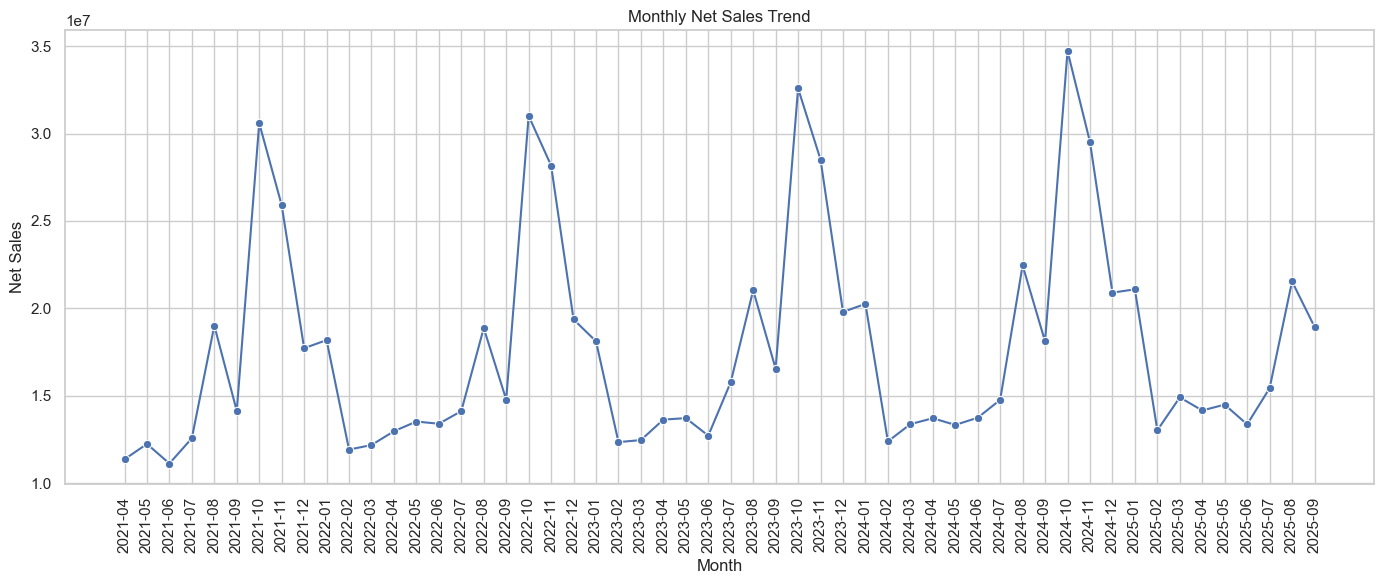

In [27]:
monthly_sales = (
    master.groupby(
        master['order_purchase_timestamp'].dt.to_period('M')
    )['Net Product Amount']
    .sum()
    .reset_index()
)

monthly_sales['order_purchase_timestamp'] = (
    monthly_sales['order_purchase_timestamp']
    .astype(str)
)

plt.figure(figsize=(14,6))

sns.lineplot(
    data=monthly_sales,
    x='order_purchase_timestamp',
    y='Net Product Amount',
    marker='o'
)

plt.title("Monthly Net Sales Trend")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [ ]:
Q2. Which product categories generate the highest sales?

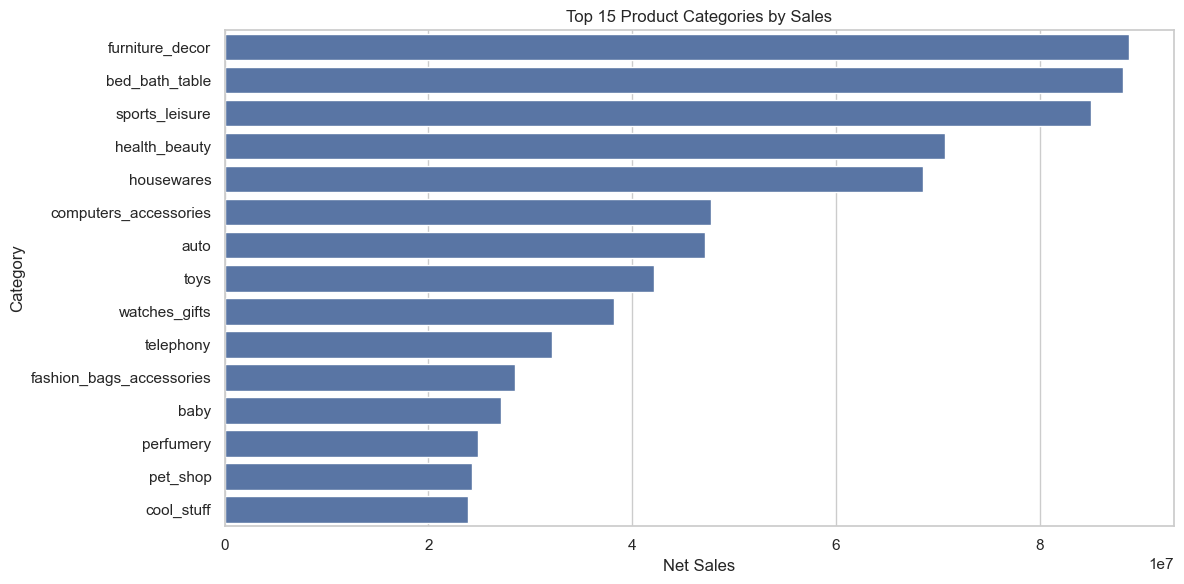

In [28]:
category_sales = (
    master.groupby('Category_name')['Net Product Amount']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_sales.values,
    y=category_sales.index
)

plt.title("Top 15 Product Categories by Sales")
plt.xlabel("Net Sales")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [ ]:
Q3. Which categories generate the highest profit?

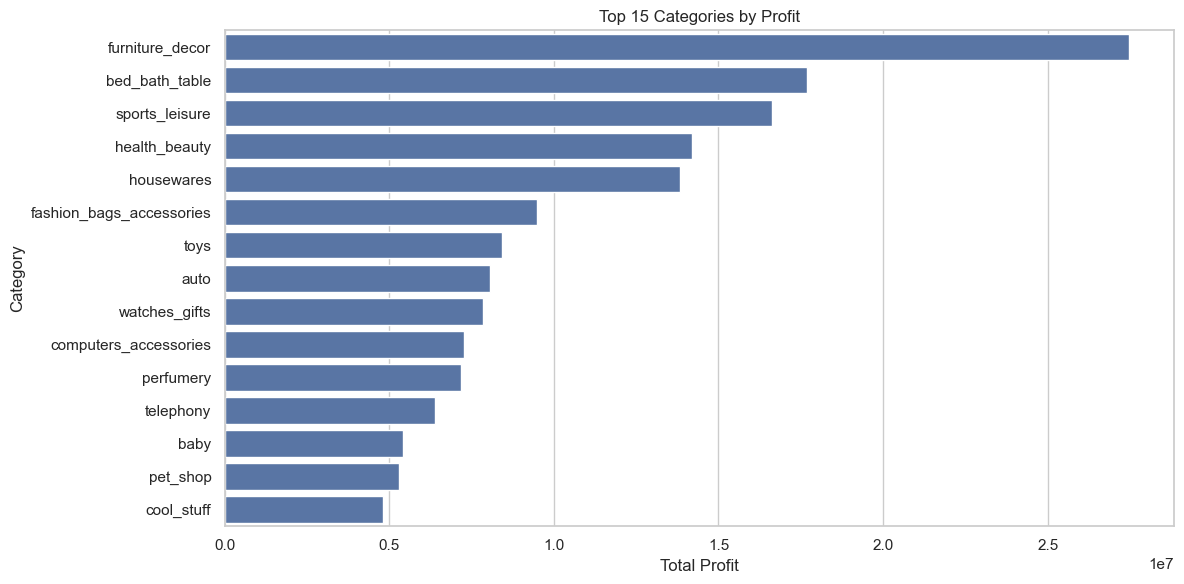

In [29]:
category_profit = (
    master.groupby('Category_name')['Profit']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_profit.values,
    y=category_profit.index
)

plt.title("Top 15 Categories by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [ ]:
Q4. Which subcategories perform best?

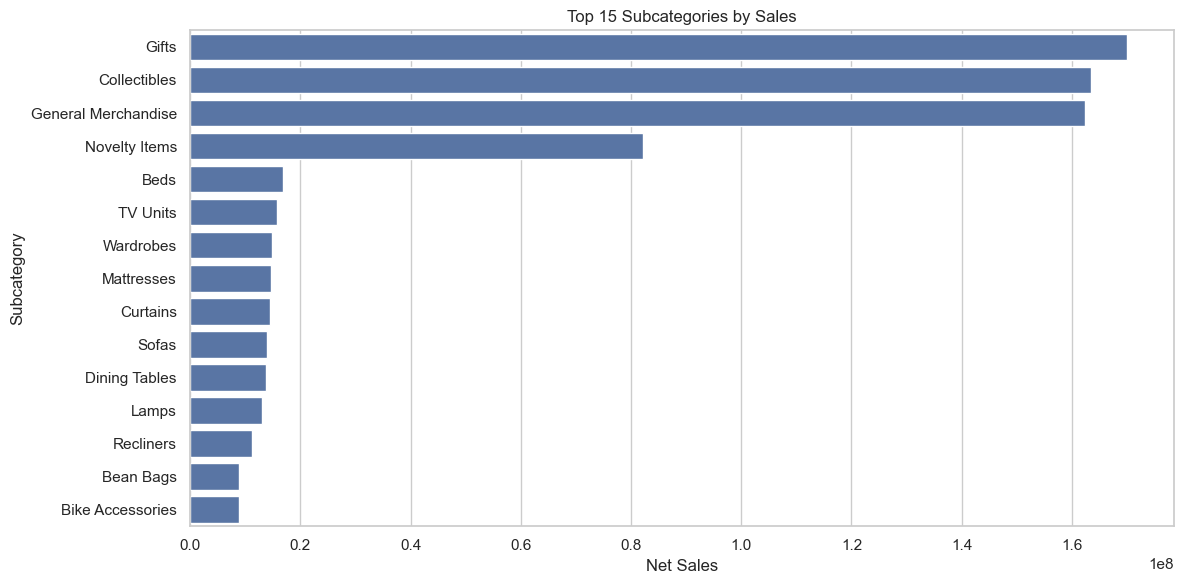

In [30]:
subcategory_sales = (
    master.groupby('sub_category_name')['Net Product Amount']
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=subcategory_sales.values,
    y=subcategory_sales.index
)

plt.title("Top 15 Subcategories by Sales")
plt.xlabel("Net Sales")
plt.ylabel("Subcategory")

plt.tight_layout()
plt.show()

In [ ]:
Q5. Which customer segments generate the most revenue?

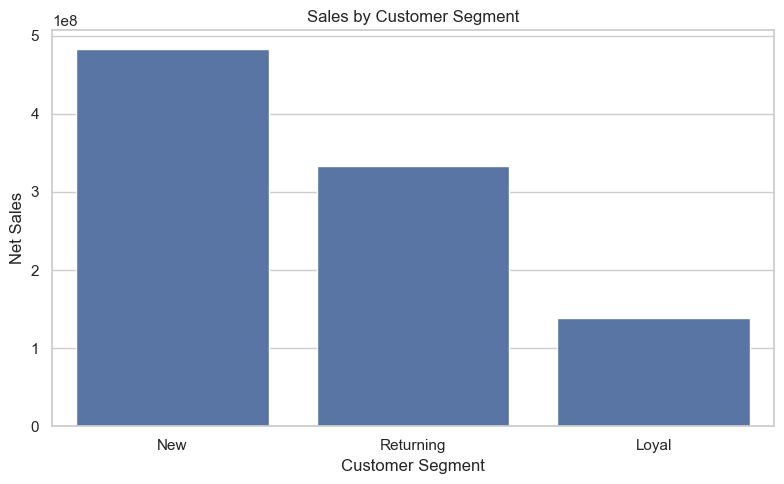

In [31]:
segment_sales = (
    master.groupby('customer_segment')['Net Product Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=segment_sales.index,
    y=segment_sales.values
)

plt.title("Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Net Sales")

plt.tight_layout()
plt.show()

In [ ]:
Q6. How many customers are New, Returning and Loyal?

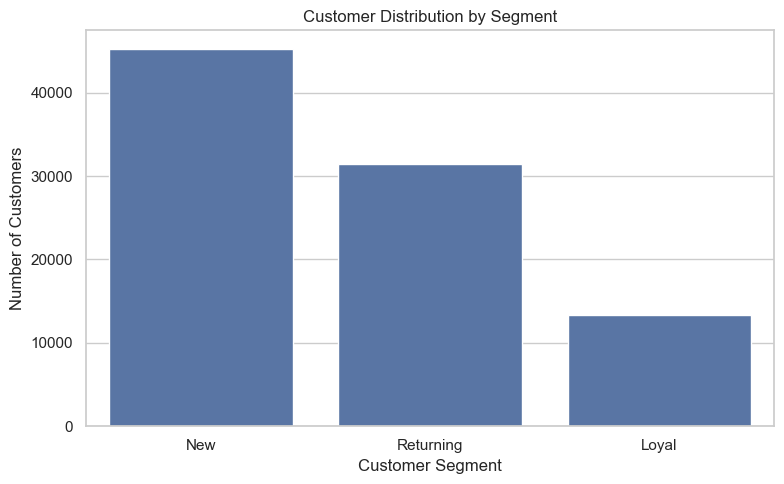

In [32]:
segment_count = customers[
    'customer_segment'
].value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=segment_count.index,
    y=segment_count.values
)

plt.title("Customer Distribution by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [ ]:
Q7. What is the average order value?

In [33]:
order_value = (
    master.groupby('order_id')['Net Product Amount']
    .sum()
)

average_order_value = order_value.mean()

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 9544.83


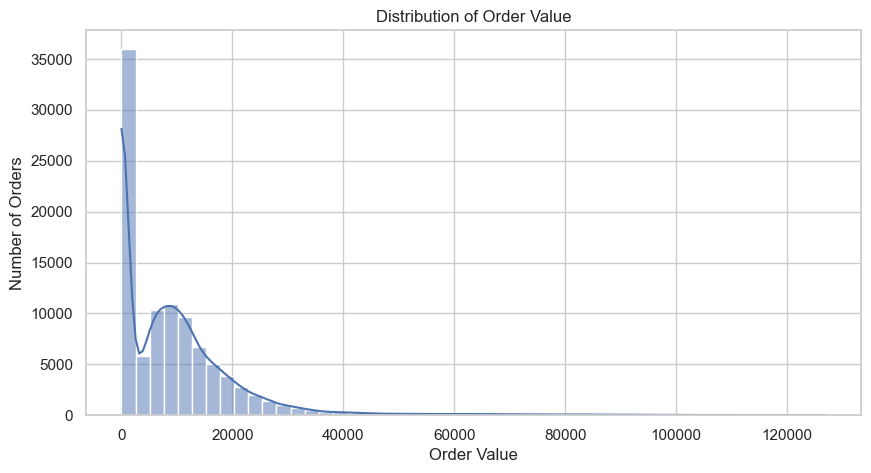

In [34]:
plt.figure(figsize=(10,5))

sns.histplot(
    order_value,
    bins=50,
    kde=True
)

plt.title("Distribution of Order Value")
plt.xlabel("Order Value")
plt.ylabel("Number of Orders")

plt.show()

In [ ]:
Q8. Which payment methods are most commonly used?

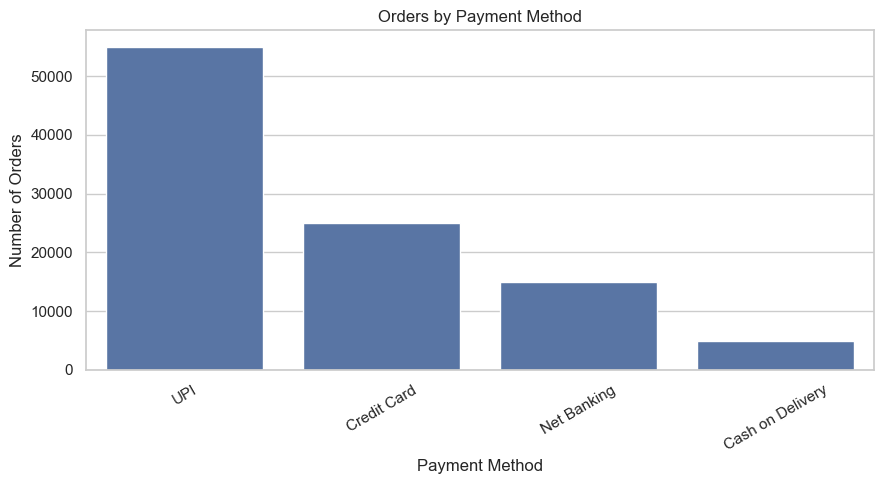

In [35]:
payment_count = orders[
    'payment_type'
].value_counts()

plt.figure(figsize=(9,5))

sns.barplot(
    x=payment_count.index,
    y=payment_count.values
)

plt.title("Orders by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Orders")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
Q9. What is the cancellation rate?

In [36]:
status_count = orders['order_status'].value_counts()

total_orders = len(orders)

cancelled_orders = (
    orders['order_status'] == 'cancelled'
).sum()

cancellation_rate = (
    cancelled_orders / total_orders
) * 100

print("Total Orders:", total_orders)
print("Cancelled Orders:", cancelled_orders)
print("Cancellation Rate:",
      round(cancellation_rate, 2), "%")

Total Orders: 99999
Cancelled Orders: 5048
Cancellation Rate: 5.05 %


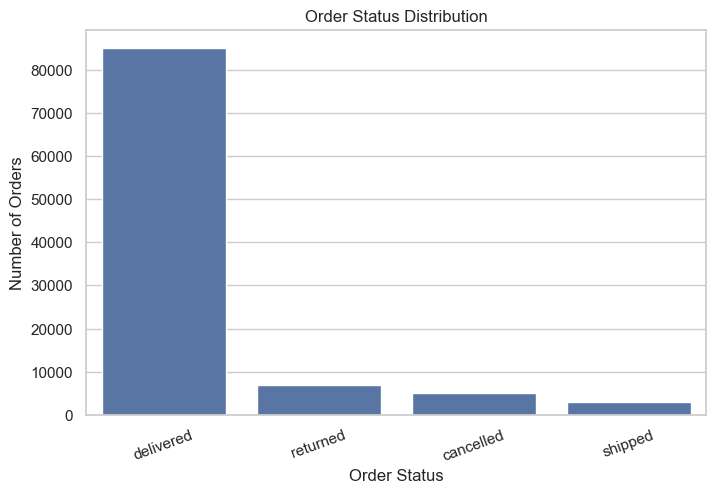

In [37]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=status_count.index,
    y=status_count.values
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=20)
plt.show()

In [ ]:
Q10. Which product categories have the highest cancellation rate?

In [38]:
cancel_category = (
    master.groupby('Category_name')
    .agg(
        total_orders=('order_id', 'nunique'),
        cancelled_orders=(
            'order_status',
            lambda x: (x == 'cancelled').sum()
        )
    )
)

cancel_category['cancellation_rate'] = (
    cancel_category['cancelled_orders'] /
    cancel_category['total_orders']
) * 100

cancel_category = (
    cancel_category
    .sort_values('cancellation_rate', ascending=False)
    .head(15)
)

display(cancel_category)

,total_orders,cancelled_orders,cancellation_rate
Category_name,,,
security_and_services,6,1,16.666667
dvds_blu_ray,257,23,8.949416
tablets_printing_image,61,5,8.196721
home_confort,110,9,8.181818
la_cuisine,49,4,8.163265
computers,38,3,7.894737
music,128,9,7.031250
office_furniture,488,32,6.557377
furniture_living_room,110,7,6.363636


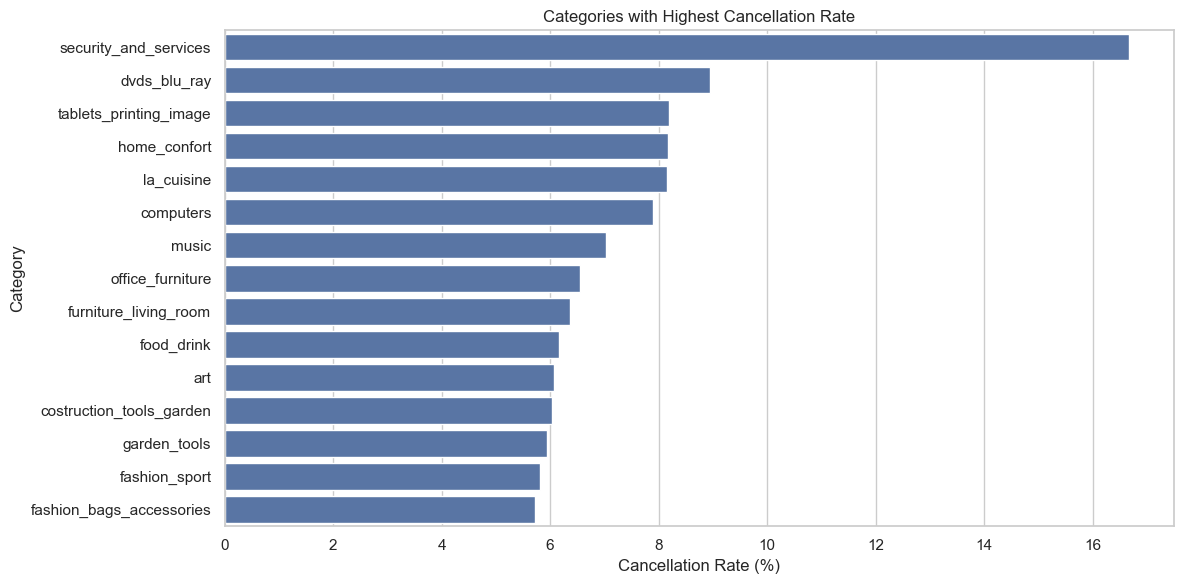

In [39]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=cancel_category.reset_index(),
    x='cancellation_rate',
    y='Category_name'
)

plt.title("Categories with Highest Cancellation Rate")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [ ]:
Q11. Which categories have the highest return rate?

In [40]:
return_category = (
    master.groupby('Category_name')
    .agg(
        total_orders=('order_id', 'nunique'),
        returned_orders=(
            'order_status',
            lambda x: (x == 'returned').sum()
        )
    )
)

return_category['return_rate'] = (
    return_category['returned_orders'] /
    return_category['total_orders']
) * 100

return_category = (
    return_category
    .sort_values('return_rate', ascending=False)
    .head(15)
)

display(return_category)

,total_orders,returned_orders,return_rate
Category_name,,,
home_comfort_2,5,1,20.000000
arts_and_craftmanship,59,9,15.254237
diapers_and_hygiene,44,6,13.636364
party_supplies,98,13,13.265306
signaling_and_security,336,37,11.011905
furniture_bedroom,39,4,10.256410
music,128,13,10.156250
kitchen_dining_laundry_garden_furniture,85,8,9.411765
home_construction,229,21,9.170306


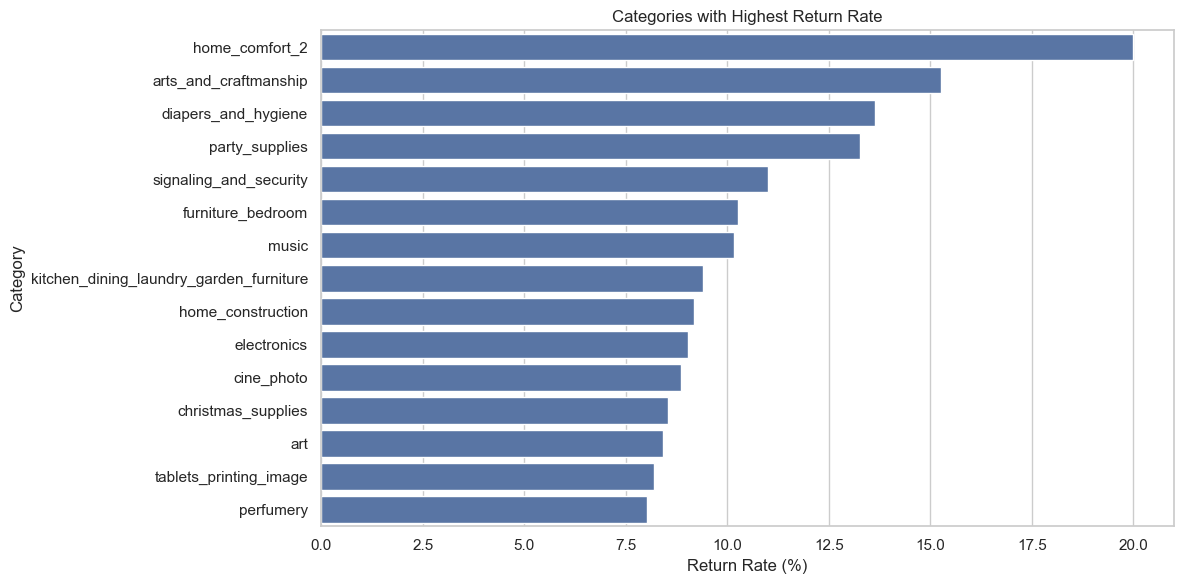

In [41]:
plt.figure(figsize=(12,6))

sns.barplot(
    data=return_category.reset_index(),
    x='return_rate',
    y='Category_name'
)

plt.title("Categories with Highest Return Rate")
plt.xlabel("Return Rate (%)")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

In [ ]:
Q12. Does delivery delay affect customer satisfaction?

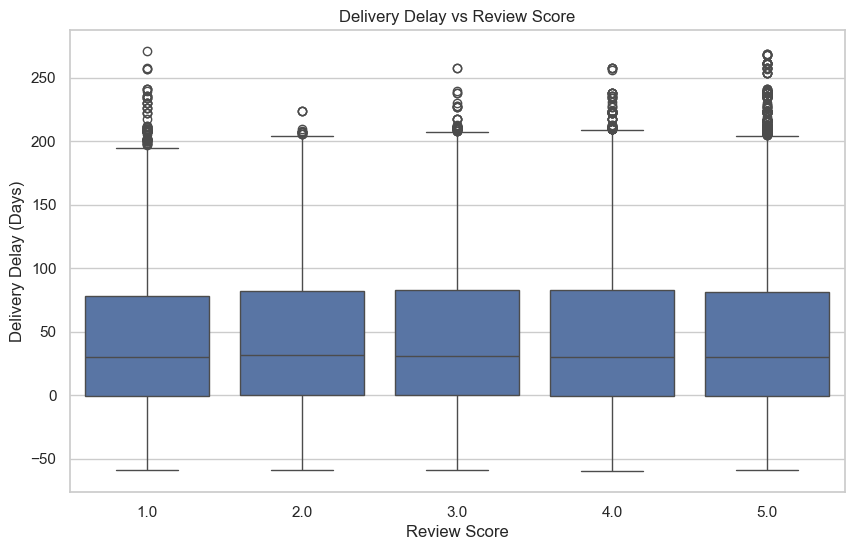

In [42]:
delivery_review = master[
    ['Delivery Delay', 'review_score']
].dropna()

plt.figure(figsize=(10,6))

sns.boxplot(
    data=delivery_review,
    x='review_score',
    y='Delivery Delay'
)

plt.title("Delivery Delay vs Review Score")
plt.xlabel("Review Score")
plt.ylabel("Delivery Delay (Days)")

plt.show()

In [43]:
correlation = delivery_review[
    ['Delivery Delay', 'review_score']
].corr()

display(correlation)

,Delivery Delay,review_score
Delivery Delay,1.000000,0.004556
review_score,0.004556,1.000000


In [ ]:
Q13. What is the relationship between review score and order status?

In [44]:
review_status = pd.crosstab(
    master['order_status'],
    master['review_score']
)

display(review_status)

review_score,1.0,2.0,3.0,4.0,5.0
order_status,,,,,
cancelled,1118,254,769,1759,5402
delivered,17718,4955,12857,30131,90241
returned,1491,376,1080,2546,7327


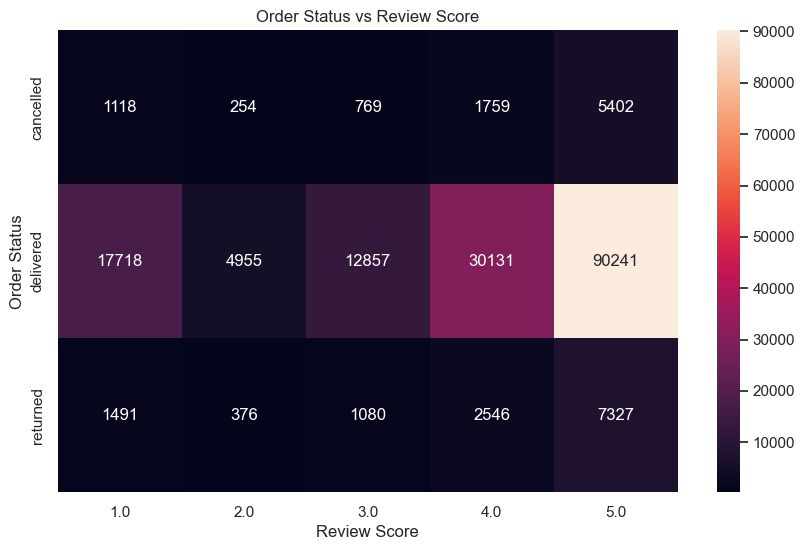

In [45]:
plt.figure(figsize=(10,6))

sns.heatmap(
    review_status,
    annot=True,
    fmt='d'
)

plt.title("Order Status vs Review Score")
plt.xlabel("Review Score")
plt.ylabel("Order Status")

plt.show()

In [ ]:
Q14. Which customer segments are most likely to return?

In [46]:
segment_return = (
    master.groupby('customer_segment')
    .agg(
        total_orders=('order_id', 'nunique'),
        returned_orders=(
            'order_status',
            lambda x: (x == 'returned').sum()
        )
    )
)

segment_return['return_rate'] = (
    segment_return['returned_orders'] /
    segment_return['total_orders']
) * 100

display(segment_return)

,total_orders,returned_orders,return_rate
customer_segment,,,
Loyal,14718,1873,12.725914
New,50121,6395,12.759123
Returning,35160,4552,12.946530


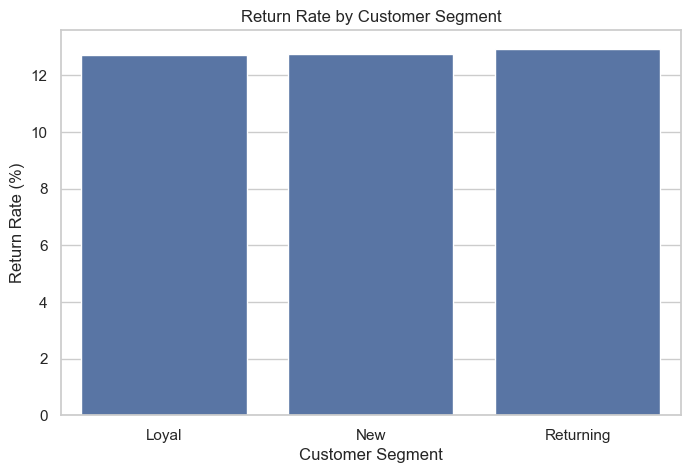

In [47]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=segment_return.reset_index(),
    x='customer_segment',
    y='return_rate'
)

plt.title("Return Rate by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Return Rate (%)")

plt.show()

In [ ]:
Q15. Which products contribute the most revenue?

In [48]:
product_sales = (
    master.groupby(
        ['product_id', 'Category_name', 'sub_category_name']
    )
    .agg(
        revenue=('Net Product Amount', 'sum'),
        quantity=('quantity', 'sum'),
        profit=('Profit', 'sum')
    )
    .sort_values(
        'revenue',
        ascending=False
    )
    .head(20)
)

display(product_sales)

,,,revenue,quantity,profit
product_id,Category_name,sub_category_name,,,
P06718,furniture_decor,Curtains,633523.914,7.0,305970.0
P07844,furniture_decor,Dining Tables,524453.292,5.0,218700.0
P09491,computers_accessories,DSL Cameras,400509.645,5.0,71200.0
P25408,home_appliances,Sofas,332475.255,6.0,155340.0
P08113,office_furniture,Beds,329460.804,4.0,79680.0
P13569,furniture_decor,Dining Tables,311388.112,3.0,80610.0
P11717,kitchen_dining_laundry_garden_furniture,Recliners,310350.150,3.0,51330.0
P20572,computers_accessories,Power Banks,302022.958,4.0,46920.0
P07096,electronics,Power Banks,300445.848,4.0,32360.0


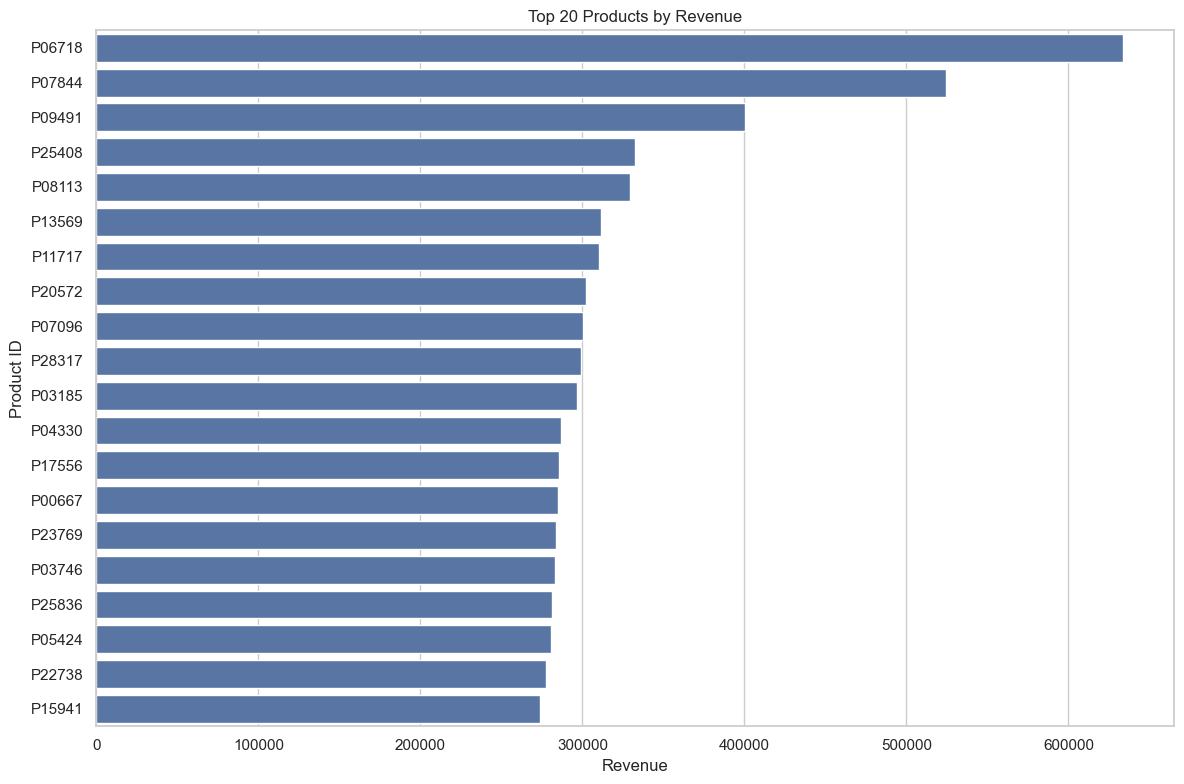

In [49]:
plt.figure(figsize=(12,8))

sns.barplot(
    data=product_sales.reset_index(),
    x='revenue',
    y='product_id'
)

plt.title("Top 20 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product ID")

plt.tight_layout()
plt.show()

In [ ]:
16. Customer Retention Analysis

In [50]:
customer_orders = (
    orders.groupby('customer_id')
    .agg(
        total_orders=('order_id', 'nunique'),
        first_purchase=('order_purchase_timestamp', 'min'),
        last_purchase=('order_purchase_timestamp', 'max')
    )
    .reset_index()
)

customer_orders['days_between_purchase'] = (
    customer_orders['last_purchase'] -
    customer_orders['first_purchase']
).dt.days

customer_orders.head()

,customer_id,total_orders,first_purchase,last_purchase,days_between_purchase
0,C00004,1,2022-01-31,2022-01-31,0
1,C00006,1,2021-07-24,2021-07-24,0
2,C00007,1,2021-09-05,2021-09-05,0
3,C00009,1,2023-11-15,2023-11-15,0
4,C00010,1,2025-03-21,2025-03-21,0


In [ ]:
17. Repeat Customer Analysis

Repeat Customer Rate: 50.44 %


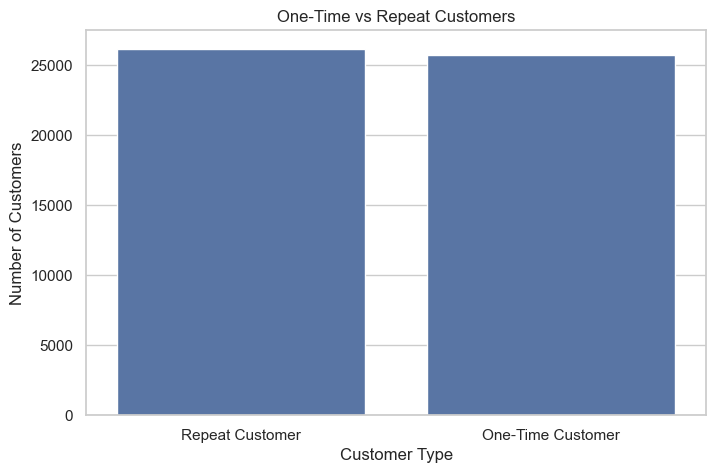

In [51]:
repeat_customers = customer_orders[
    customer_orders['total_orders'] > 1
]

repeat_customer_rate = (
    len(repeat_customers) /
    len(customer_orders)
) * 100

print(
    "Repeat Customer Rate:",
    round(repeat_customer_rate, 2),
    "%"
)

customer_type = np.where(
    customer_orders['total_orders'] > 1,
    'Repeat Customer',
    'One-Time Customer'
)

customer_type_counts = pd.Series(
    customer_type
).value_counts()

plt.figure(figsize=(8,5))

sns.barplot(
    x=customer_type_counts.index,
    y=customer_type_counts.values
)

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
18. Customer Purchase Frequency

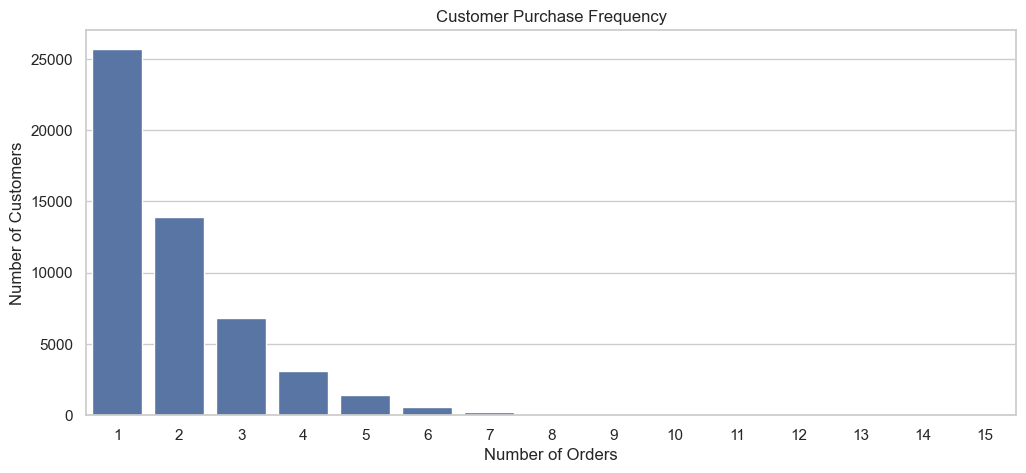

In [52]:
purchase_frequency = (
    customer_orders['total_orders']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12,5))

sns.barplot(
    x=purchase_frequency.index,
    y=purchase_frequency.values
)

plt.title("Customer Purchase Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.show()

In [ ]:
19. Customer Segment vs Purchase Frequency

customer_segment
Loyal        1.928459
Returning    1.927420
New          1.926175
Name: total_orders, dtype: float64

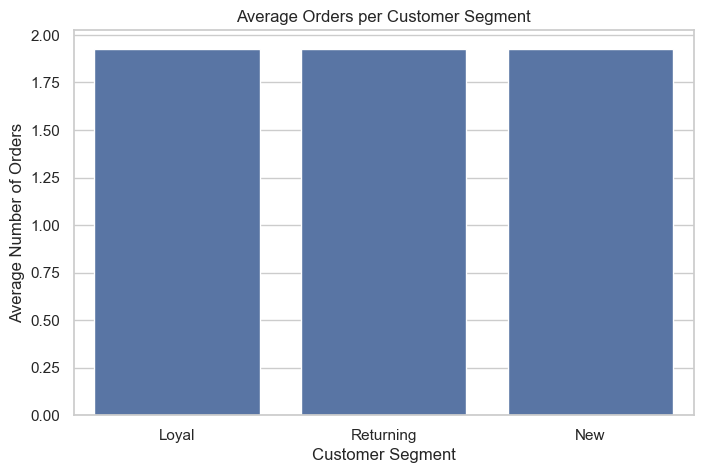

In [53]:
customer_analysis = customer_orders.merge(
    customers[
        ['customer_id', 'customer_segment', 'age_group', 'gender']
    ],
    on='customer_id',
    how='left'
)

segment_frequency = (
    customer_analysis.groupby('customer_segment')
    ['total_orders']
    .mean()
    .sort_values(ascending=False)
)

display(segment_frequency)

plt.figure(figsize=(8,5))

sns.barplot(
    x=segment_frequency.index,
    y=segment_frequency.values
)

plt.title("Average Orders per Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Number of Orders")

plt.show()

In [ ]:
20. Age Group Analysis

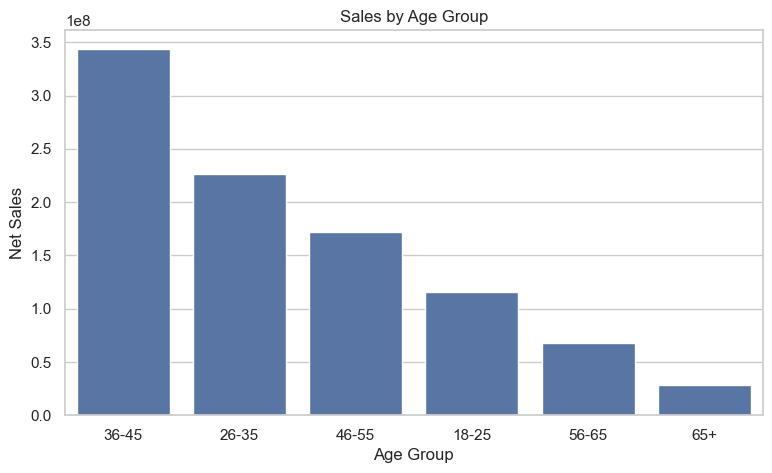

In [54]:
age_sales = (
    master.groupby('age_group')['Net Product Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9,5))

sns.barplot(
    x=age_sales.index,
    y=age_sales.values
)

plt.title("Sales by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Net Sales")

plt.show()

In [ ]:
21. Gender Analysis

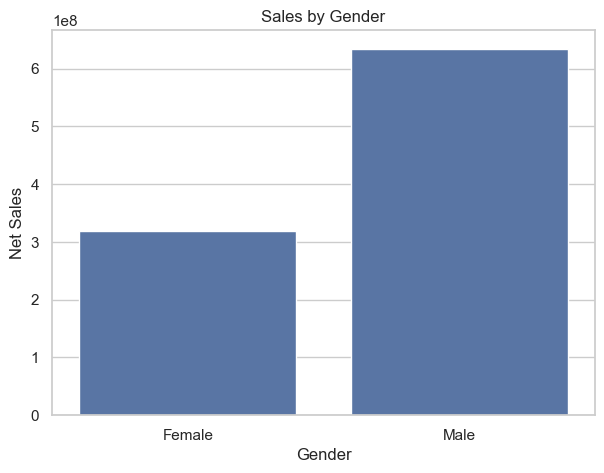

In [55]:
gender_sales = (
    master.groupby('gender')['Net Product Amount']
    .sum()
)

plt.figure(figsize=(7,5))

sns.barplot(
    x=gender_sales.index,
    y=gender_sales.values
)

plt.title("Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Net Sales")

plt.show()

In [ ]:
22. Discount vs Sales Analysis

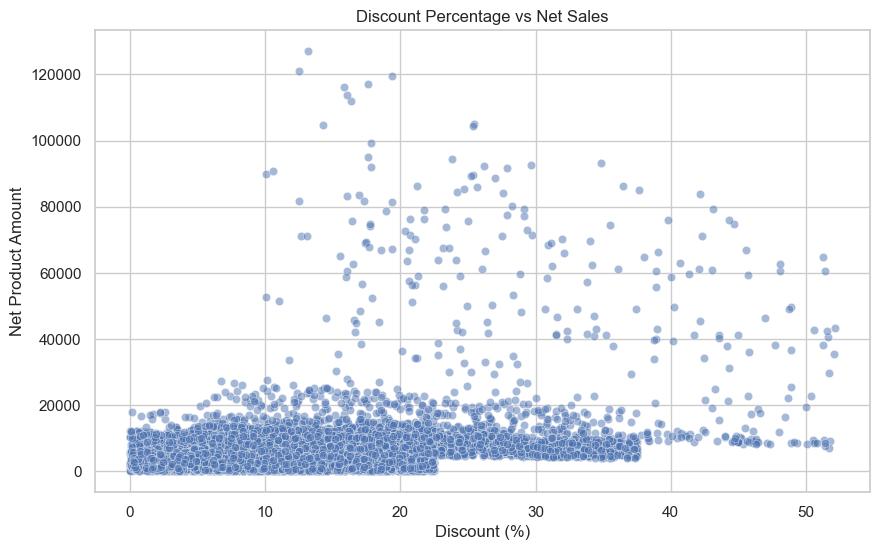

In [56]:
discount_analysis = master[
    ['discount(%)', 'Net Product Amount']
].dropna()

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=discount_analysis.sample(
        min(10000, len(discount_analysis)),
        random_state=42
    ),
    x='discount(%)',
    y='Net Product Amount',
    alpha=0.5
)

plt.title("Discount Percentage vs Net Sales")
plt.xlabel("Discount (%)")
plt.ylabel("Net Product Amount")

plt.show()

In [ ]:
23. Profit Margin Analysis

In [57]:
profit_category = (
    master.groupby('Category_name')
    .agg(
        revenue=('Net Product Amount', 'sum'),
        profit=('Profit', 'sum')
    )
)

profit_category['profit_margin'] = (
    profit_category['profit'] /
    profit_category['revenue']
) * 100

profit_category = (
    profit_category
    .sort_values('profit_margin', ascending=False)
)

display(profit_category.head(15))

,revenue,profit,profit_margin
Category_name,,,
fashion_sport,7.650588e+05,273130.0,35.700525
fashion_childrens_clothes,1.150893e+05,40020.0,34.772999
small_appliances_home_oven_and_coffee,1.148464e+06,397640.0,34.623636
home_comfort_2,4.131160e+05,142320.0,34.450374
furniture_bedroom,1.453445e+06,493770.0,33.972384
home_appliances_2,3.398573e+06,1147860.0,33.774766
furniture_living_room,4.154339e+06,1398860.0,33.672264
fashion_bags_accessories,2.848018e+07,9483080.0,33.297121
fashion_shoes,6.229036e+06,2046090.0,32.847618


In [ ]:
24. Delivery Status Analysis

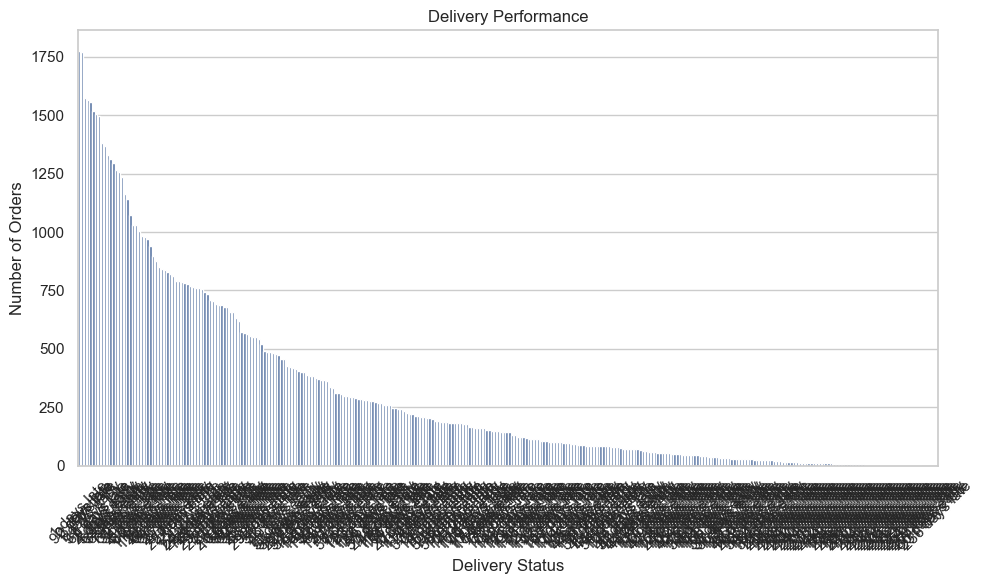

In [58]:
delivery_status = (
    orders['Delivery_Status']
    .value_counts()
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=delivery_status.index,
    y=delivery_status.values
)

plt.title("Delivery Performance")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
25. Monthly Order Trend

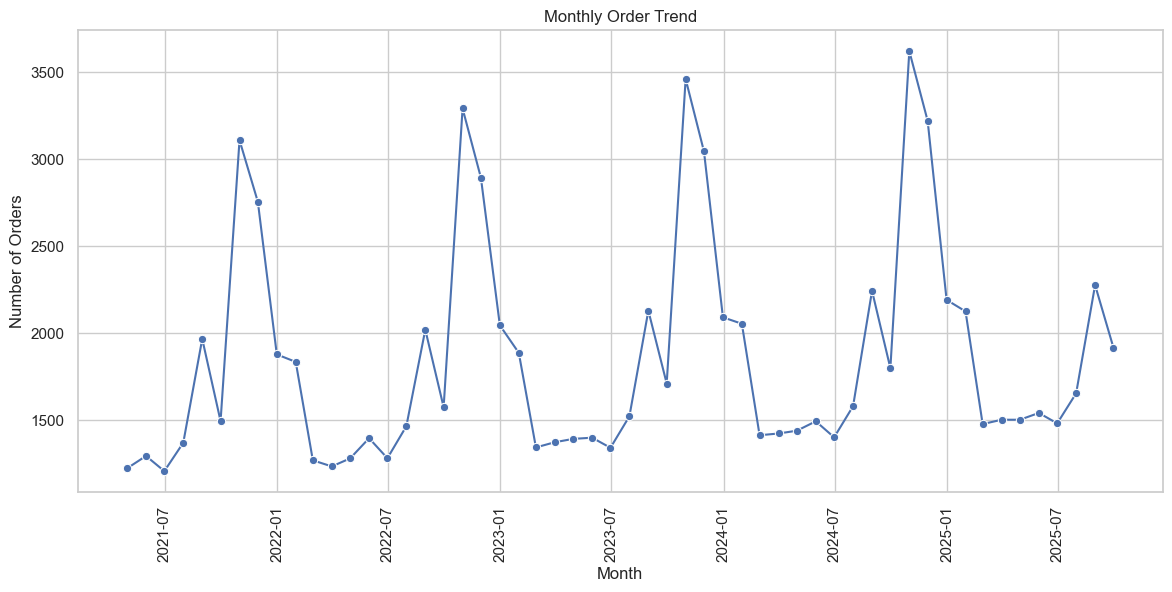

In [59]:
monthly_orders = (
    orders.set_index('order_purchase_timestamp')
    .resample('M')
    ['order_id']
    .nunique()
)

plt.figure(figsize=(14,6))

sns.lineplot(
    x=monthly_orders.index,
    y=monthly_orders.values,
    marker='o'
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=90)
plt.show()

In [ ]:
26. Review Score Distribution

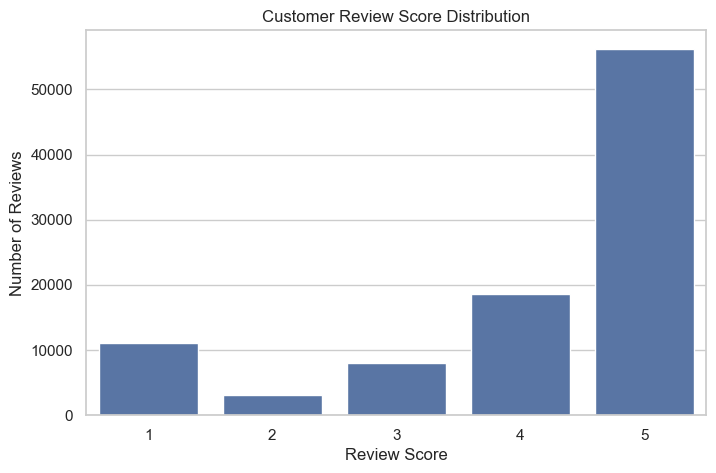

In [60]:
review_distribution = (
    reviews['review_score']
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=review_distribution.index,
    y=review_distribution.values
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

In [ ]:
27. Average Review Score by Category

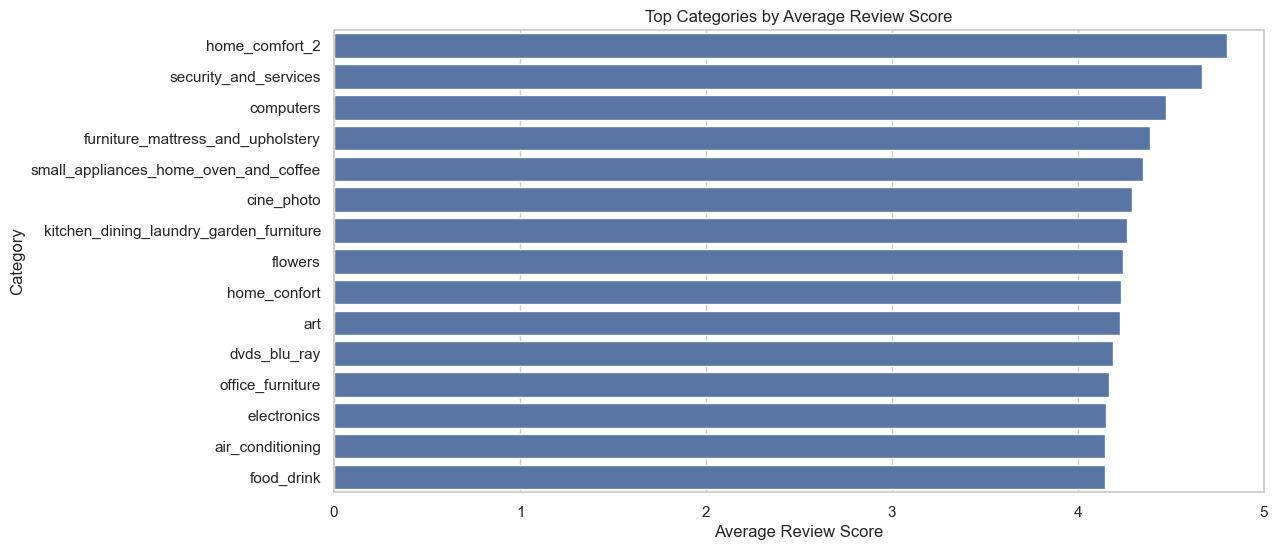

In [61]:
category_reviews = (
    master.groupby('Category_name')
    ['review_score']
    .mean()
    .sort_values(ascending=False)
    .head(15)
)

plt.figure(figsize=(12,6))

sns.barplot(
    x=category_reviews.values,
    y=category_reviews.index
)

plt.title("Top Categories by Average Review Score")
plt.xlabel("Average Review Score")
plt.ylabel("Category")

plt.xlim(0,5)

plt.show()

In [ ]:
28. Correlation Analysis

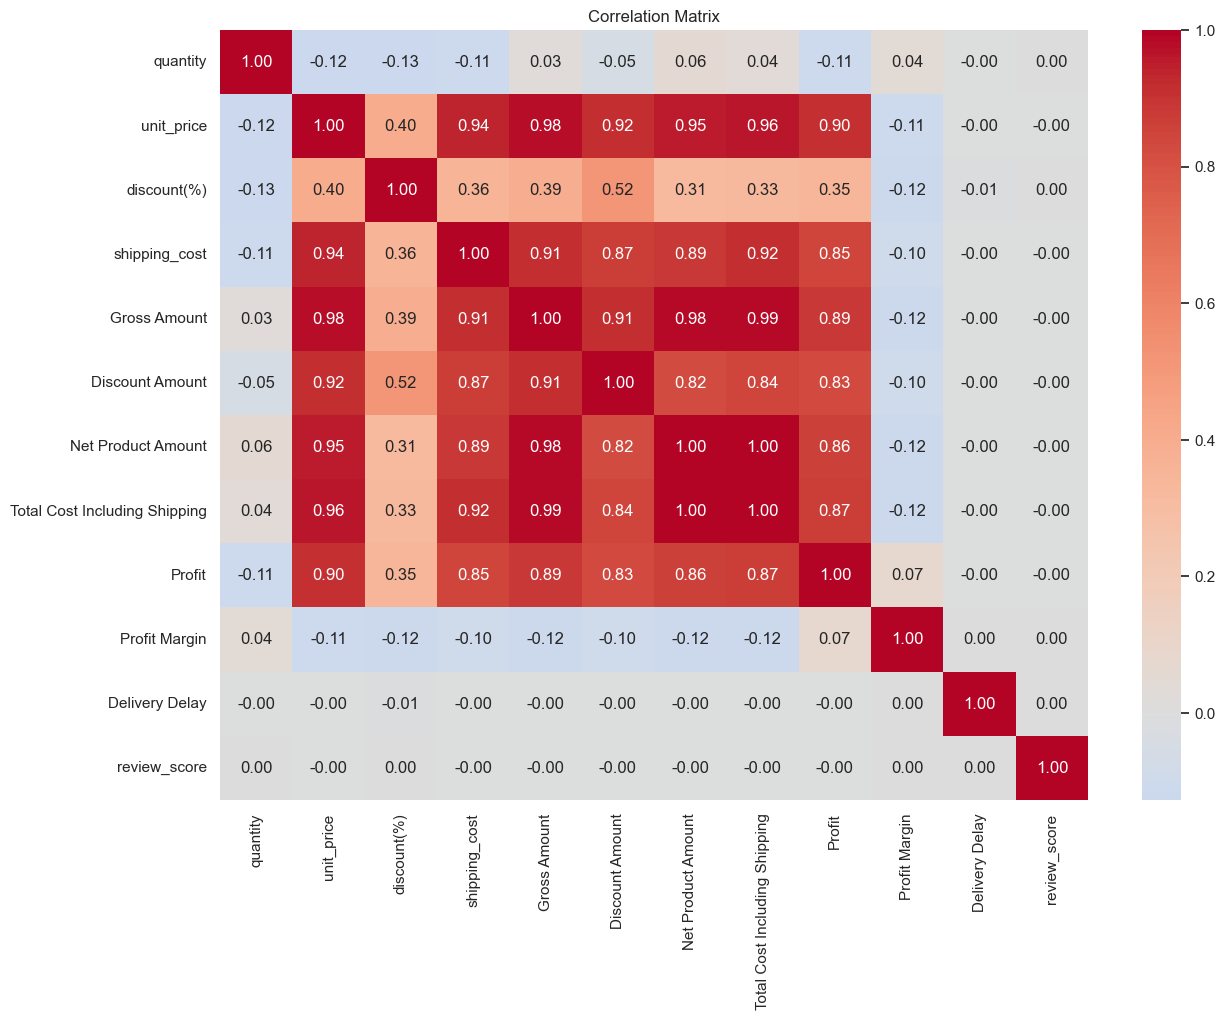

In [62]:
numeric_columns = [
    'quantity',
    'unit_price',
    'discount(%)',
    'shipping_cost',
    'Gross Amount',
    'Discount Amount',
    'Net Product Amount',
    'Total Cost Including Shipping',
    'Profit',
    'Profit Margin',
    'Delivery Delay',
    'review_score'
]

corr_data = master[
    [col for col in numeric_columns if col in master.columns]
].corr()

plt.figure(figsize=(14,10))

sns.heatmap(
    corr_data,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title("Correlation Matrix")

plt.show()

In [ ]:
29. Key KPI Calculation

In [63]:
total_orders = orders['order_id'].nunique()

total_customers = customers['customer_id'].nunique()

total_revenue = master[
    'Net Product Amount'
].sum()

total_profit = master[
    'Profit'
].sum()

cancelled_orders = (
    orders['order_status'] == 'cancelled'
).sum()

returned_orders = (
    orders['order_status'] == 'returned'
).sum()

cancellation_rate = (
    cancelled_orders / total_orders
) * 100

return_rate = (
    returned_orders / total_orders
) * 100

average_order_value = (
    master.groupby('order_id')['Net Product Amount']
    .sum()
    .mean()
)

average_review = reviews[
    'review_score'
].mean()

print("========== E-COMMERCE KPIs ==========")
print("Total Customers       :", total_customers)
print("Total Orders          :", total_orders)
print("Total Revenue         :", round(total_revenue, 2))
print("Total Profit          :", round(total_profit, 2))
print("Average Order Value   :", round(average_order_value, 2))
print("Cancellation Rate     :", round(cancellation_rate, 2), "%")
print("Return Rate           :", round(return_rate, 2), "%")
print("Average Review Score  :", round(average_review, 2))
print("Repeat Customer Rate  :", round(repeat_customer_rate, 2), "%")


========== E-COMMERCE KPIs ==========
Total Customers       : 90000
Total Orders          : 99999
Total Revenue         : 954473907.12
Total Profit          : 208636970.0
Average Order Value   : 9544.83
Cancellation Rate     : 5.05 %
Return Rate           : 7.0 %
Average Review Score  : 4.09
Repeat Customer Rate  : 50.44 %


In [ ]:
30. Automatic Top Business Insights

In [64]:
top_category = (
    master.groupby('Category_name')['Net Product Amount']
    .sum()
    .idxmax()
)

top_category_sales = (
    master.groupby('Category_name')['Net Product Amount']
    .sum()
    .max()
)

top_profit_category = (
    master.groupby('Category_name')['Profit']
    .sum()
    .idxmax()
)

top_customer_segment = (
    master.groupby('customer_segment')
    ['Net Product Amount']
    .sum()
    .idxmax()
)

highest_cancel_category = (
    cancel_category.index[0]
)

highest_return_category = (
    return_category.index[0]
)

print("KEY BUSINESS INSIGHTS")
print("-" * 50)

print(
    f"1. {top_category} generates the highest net sales."
)

print(
    f"2. {top_profit_category} is the most profitable category."
)

print(
    f"3. {top_customer_segment} customers contribute the highest revenue."
)

print(
    f"4. Overall cancellation rate is {cancellation_rate:.2f}%."
)

print(
    f"5. Overall return rate is {return_rate:.2f}%."
)

print(
    f"6. {highest_cancel_category} has the highest cancellation rate among categories."
)

print(
    f"7. {highest_return_category} has the highest return rate among categories."
)

print(
    f"8. Repeat customer rate is {repeat_customer_rate:.2f}%."
)

print(
    f"9. Average customer review score is {average_review:.2f}/5."
)

KEY BUSINESS INSIGHTS
--------------------------------------------------
1. furniture_decor generates the highest net sales.
2. furniture_decor is the most profitable category.
3. New customers contribute the highest revenue.
4. Overall cancellation rate is 5.05%.
5. Overall return rate is 7.00%.
6. security_and_services has the highest cancellation rate among categories.
7. home_comfort_2 has the highest return rate among categories.
8. Repeat customer rate is 50.44%.
9. Average customer review score is 4.09/5.


In [ ]:
31. Final EDA Dashboard in Python

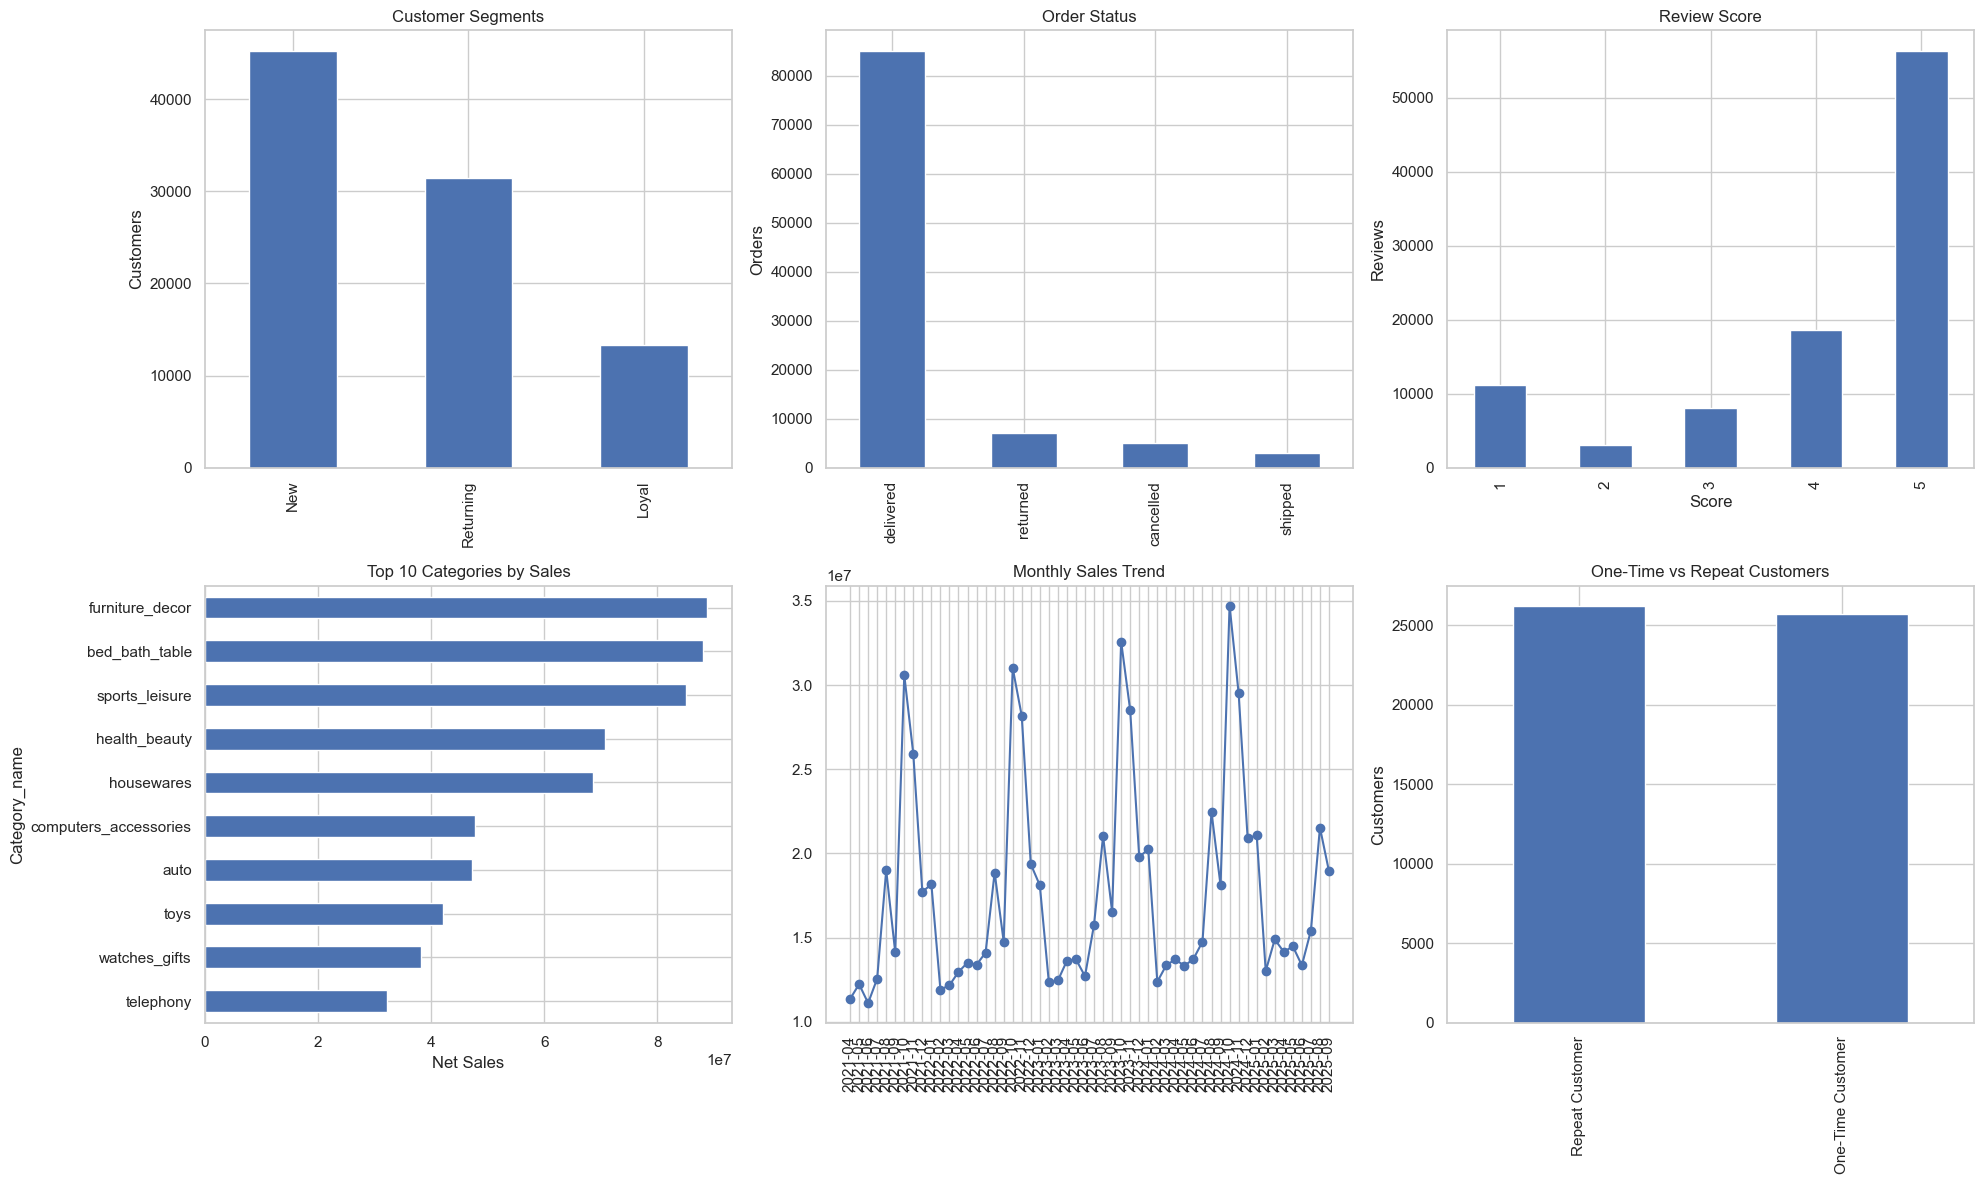

In [65]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))

# 1. Customer Segment
segment_count.plot(
    kind='bar',
    ax=axes[0,0]
)
axes[0,0].set_title("Customer Segments")
axes[0,0].set_xlabel("")
axes[0,0].set_ylabel("Customers")

# 2. Order Status
status_count.plot(
    kind='bar',
    ax=axes[0,1]
)
axes[0,1].set_title("Order Status")
axes[0,1].set_xlabel("")
axes[0,1].set_ylabel("Orders")

# 3. Review Score
review_distribution.plot(
    kind='bar',
    ax=axes[0,2]
)
axes[0,2].set_title("Review Score")
axes[0,2].set_xlabel("Score")
axes[0,2].set_ylabel("Reviews")

# 4. Top Categories
category_sales.head(10).sort_values().plot(
    kind='barh',
    ax=axes[1,0]
)
axes[1,0].set_title("Top 10 Categories by Sales")
axes[1,0].set_xlabel("Net Sales")

# 5. Monthly Sales
axes[1,1].plot(
    monthly_sales['order_purchase_timestamp'],
    monthly_sales['Net Product Amount'],
    marker='o'
)
axes[1,1].set_title("Monthly Sales Trend")
axes[1,1].tick_params(axis='x', rotation=90)

# 6. Customer Type
customer_type_counts.plot(
    kind='bar',
    ax=axes[1,2]
)
axes[1,2].set_title("One-Time vs Repeat Customers")
axes[1,2].set_xlabel("")
axes[1,2].set_ylabel("Customers")

plt.tight_layout()
plt.show()